In [12]:
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

In [3]:
train = pd.read_csv("mnist_train.csv")
test = pd.read_csv("mnist_test.csv")

x_train = train.drop("label",axis=1).values
y_train = train["label"].values

x_test = test.drop("label",axis=1).values
y_test = test["label"].values

x_train=x_train.reshape(-1,28,28,1)
x_test=x_test.reshape(-1,28,28,1)

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28, 1)
(60000,)
(10000, 28, 28, 1)
(10000,)


In [4]:
model = keras.Sequential([    
    keras.Input(shape=(28,28,1)),
    layers.Conv2D(32,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),                 
    layers.Dense(10,activation="softmax")                
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 5408)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │          54,090 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 54,410 (212.54 KB)

 Trainable params: 54,410 (212.54 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [6]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 16ms/step - accuracy: 0.9324 - loss: 0.8848 - val_accuracy: 0.9737 - val_loss: 0.1321
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9749 - loss: 0.0969 - val_accuracy: 0.9783 - val_loss: 0.0951
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9820 - loss: 0.0611 - val_accuracy: 0.9777 - val_loss: 0.1017
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9850 - loss: 0.0492 - val_accuracy: 0.9787 - val_loss: 0.1018
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9865 - loss: 0.0437 - val_accuracy: 0.9765 - val_loss: 0.1126


In [7]:
test_loss,test_accuracy = model.evaluate(x_test,y_test)
print("Test loss:",test_loss)
print("Test accuracy:",test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9742 - loss: 0.1225
Test loss: 0.12247396260499954
Test accuracy: 0.9742000102996826


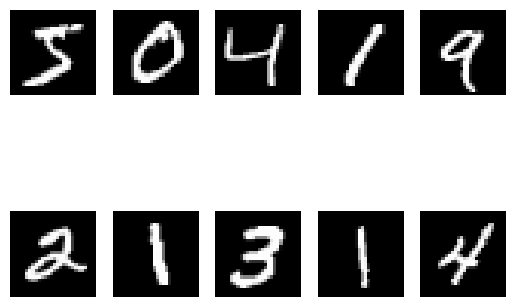

In [8]:
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i].reshape(28,28),cmap="gray")
    plt.axis("off")
plt.show()

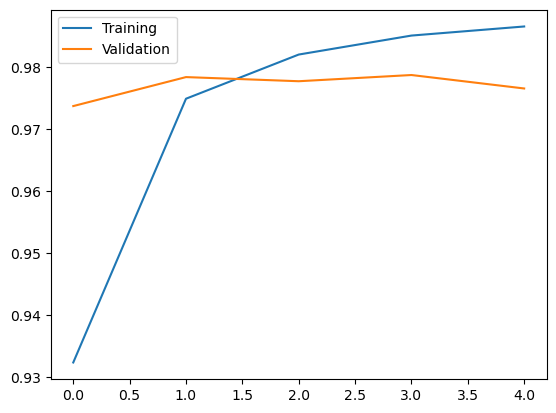

In [9]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.legend()
plt.show()

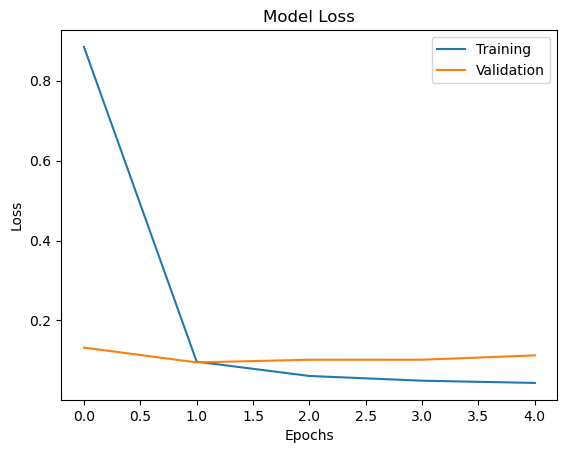

In [10]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [13]:
prediction = model.predict(x_test[:1])
predicted = np.argmax(prediction[0])
actual = y_test[0]

print("actual",actual)
print(predicted)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
actual 7
7


(60000, 28, 28, 1)
(60000,)
(10000, 28, 28, 1)
(10000,)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 5408)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │          54,090 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 54,410 (212.54 KB)

 Trainable params: 54,410 (212.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step - accuracy: 0.9284 - loss: 0.6803 - val_accuracy: 0.9705 - val_loss: 0.1301
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9751 - loss: 0.0923 - val_accuracy: 0.9743 - val_loss: 0.1151
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - accuracy: 0.9820 - loss: 0.0607 - val_accuracy: 0.9780 - val_loss: 0.0962
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9857 - loss: 0.0456 - val_accuracy: 0.9788 - val_loss: 0.1070
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9870 - loss: 0.0411 - val_accuracy: 0.9782 - val_loss: 0.1220
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9717 - loss: 0.1399
Test loss: 0.13989302515983582
Test accuracy: 0.9717000126838684


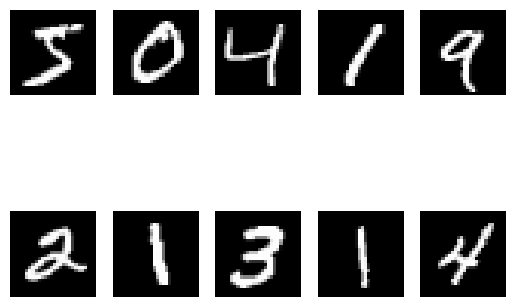

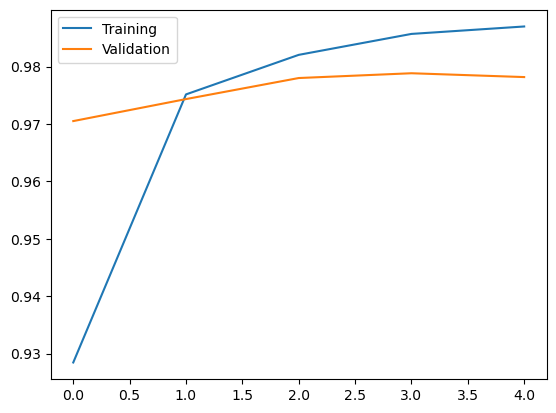

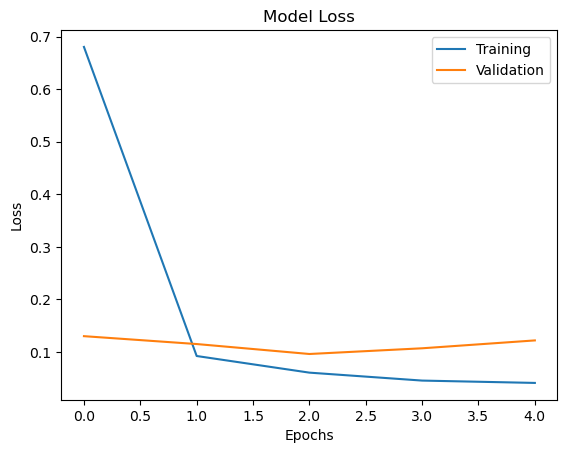

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
actual 7
7


In [14]:
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

train = pd.read_csv("mnist_train.csv")
test = pd.read_csv("mnist_test.csv")

x_train = train.drop("label",axis=1).values
y_train = train["label"].values

x_test = test.drop("label",axis=1).values
y_test = test["label"].values

x_train=x_train.reshape(-1,28,28,1)
x_test=x_test.reshape(-1,28,28,1)

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

model = keras.Sequential([    
    keras.Input(shape=(28,28,1)),
    layers.Conv2D(32,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),                 
    layers.Dense(10,activation="softmax")                
])
model.summary()

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

test_loss,test_accuracy = model.evaluate(x_test,y_test)
print("Test loss:",test_loss)
print("Test accuracy:",test_accuracy)

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i].reshape(28,28),cmap="gray")
    plt.axis("off")
plt.show()

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

prediction = model.predict(x_test[:1])
predicted = np.argmax(prediction[0])
actual = y_test[0]

print("actual",actual)
print(predicted)